In [1]:
import pandas as pd

website = pd.read_csv("../data/kavak_listings.csv")
market = pd.read_csv("../data/final_dataset.csv")

# Only KAVAK listings on YallaMotor
market = market[market["dealer"] == "KAVAK"].copy()

# Standardize column names
website = website.rename(columns={
    "Make": "make",
    "Year": "year",
    "Mileage KM": "mileage_km",
    "Price AED": "price_aed",
    "Model Page URL": "website_url"
})

# Standardize make names
for df in [website, market]:
    df["make_key"] = (
        df["make"].str.lower()
        .str.replace(r"[^a-z0-9]", "", regex=True)
    )

In [2]:
keys = ["make_key", "year", "mileage_km"]

web_unique = website.drop_duplicates(keys, keep=False)
market_unique = market.drop_duplicates(keys, keep=False)

matched = web_unique.merge(
    market_unique,
    on=keys,
    suffixes=("_web", "_market"),
    validate="one_to_one"
)

website["on_yallamotor"] = website["website_url"].isin(
    matched["website_url"]
)

print("Website listings:", len(website))
print("YallaMotor listings:", len(market))
print("Probable matches:", len(matched))

print(
    "Website coverage:",
    round(website["on_yallamotor"].mean() * 100, 1), "%"
)

print(
    "YallaMotor coverage:",
    round(len(matched) / len(market) * 100, 1), "%"
)

Website listings: 776
YallaMotor listings: 552
Probable matches: 534
Website coverage: 68.8 %
YallaMotor coverage: 96.7 %


In [3]:
coverage = website.groupby("year")["on_yallamotor"].agg(
    ["sum", "count"]
)

coverage.columns = ["On YallaMotor", "Website Total"]

coverage["Coverage %"] = (
    coverage["On YallaMotor"]
    / coverage["Website Total"] * 100
).round(1)

display(coverage)

,On YallaMotor,Website Total,Coverage %
year,,,
2017,5,5,100.0
2018,14,18,77.8
2019,17,27,63.0
2020,25,43,58.1
2021,43,61,70.5
2022,63,93,67.7
2023,119,157,75.8
2024,122,165,73.9
2025,90,130,69.2


In [4]:
matched["price_difference"] = (
    matched["price_aed_market"] - matched["price_aed_web"]
)

print("Same advertised price:",
      (matched["price_difference"] == 0).sum())

# Review large price discrepancies
review = matched[
    matched["price_difference"].abs() > 5000
]

display(review[[
    "make_web",
    "Model",
    "model",
    "year",
    "mileage_km",
    "price_aed_web",
    "price_aed_market",
    "website_url",
    "url"
]])

Same advertised price: 472


,make_web,Model,model,year,mileage_km,price_aed_web,price_aed_market,website_url,url
39,Volkswagen,T-Roc,T-Roc,2024,61075,56199,46999,https://www.kavak.com/ae/cars-for-sale/volkswa...,https://uae.yallamotor.com/used-cars/volkswage...
40,Mercedes Benz,GLC-Class Coupe,GLC-Class,2023,44702,168999,159999,https://www.kavak.com/ae/cars-for-sale/mercede...,https://uae.yallamotor.com/used-cars/mercedes-...
69,Peugeot,3008,3008,2026,5788,91999,83499,https://www.kavak.com/ae/cars-for-sale/peugeot...,https://uae.yallamotor.com/used-cars/peugeot/3...
71,Audi,A3,A3 Sedan,2025,7149,121999,114999,https://www.kavak.com/ae/cars-for-sale/audi-a3...,https://uae.yallamotor.com/used-cars/audi/a3-s...
80,Ford,Edge,Edge,2022,84721,83999,60999,https://www.kavak.com/ae/cars-for-sale/ford-ed...,https://uae.yallamotor.com/used-cars/ford/edge...
103,Mitsubishi,Attrage,Attrage,2025,25132,37999,28499,https://www.kavak.com/ae/cars-for-sale/mitsubi...,https://uae.yallamotor.com/used-cars/mitsubish...
244,Audi,Q3,Q3,2024,39985,122999,94999,https://www.kavak.com/ae/cars-for-sale/audi-q3...,https://uae.yallamotor.com/used-cars/audi/q3/2...
279,Chery,Tiggo 4 Pro,Tiggo 4 Pro,2026,382,62999,45999,https://www.kavak.com/ae/cars-for-sale/chery-t...,https://uae.yallamotor.com/used-cars/chery/tig...
374,Renault,Duster,Duster,2025,19185,42999,37599,https://www.kavak.com/ae/cars-for-sale/renault...,https://uae.yallamotor.com/used-cars/renault/d...
529,Nissan,Altima,Altima,2024,56723,66999,57999,https://www.kavak.com/ae/cars-for-sale/nissan-...,https://uae.yallamotor.com/used-cars/nissan/al...


,KAVAK Website,YallaMotor
make_key,,
nissan,9.9,9.1
mg,7.0,3.6
toyota,6.6,6.9
mitsubishi,5.7,5.3
bmw,4.6,5.3
volkswagen,4.4,5.3
hyundai,4.3,4.7
chevrolet,4.1,5.1
jeep,3.7,4.3


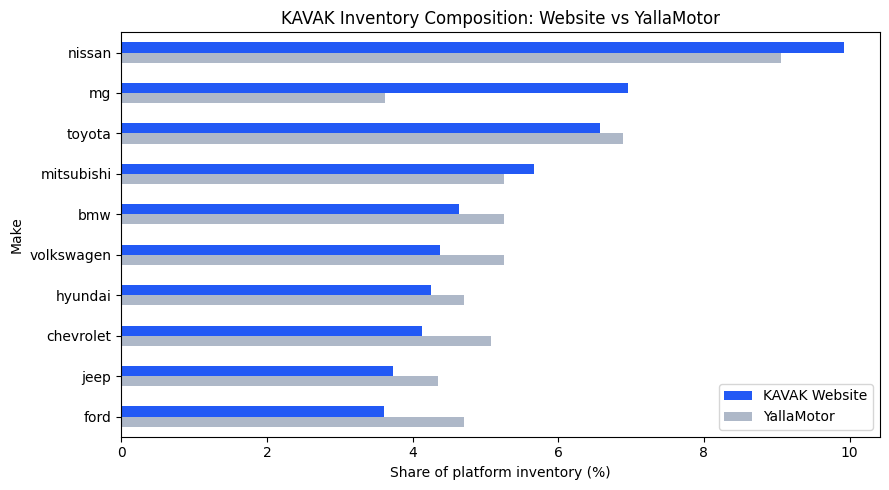

In [6]:
# Compare make distribution between platforms

comparison = pd.DataFrame({
    "KAVAK Website": website["make_key"].value_counts(normalize=True) * 100,
    "YallaMotor": market["make_key"].value_counts(normalize=True) * 100
}).fillna(0)

# Show the 10 most common makes on KAVAK's website
top_makes = website["make_key"].value_counts().head(10).index
comparison = comparison.loc[top_makes]

display(comparison.round(1))

comparison.plot(
    kind="barh",
    figsize=(9, 5),
    color=["#2259F5", "#AEB8C8"]
)

plt.xlabel("Share of platform inventory (%)")
plt.ylabel("Make")
plt.title("KAVAK Inventory Composition: Website vs YallaMotor")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()